1.Fornt loder


In [12]:
import os, urllib.request
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

# ดาวน์โหลด NotoSansThai (ฟรี, รองรับภาษาไทย 100%)
font_path = "NotoSansThai.ttf"
if not os.path.exists(font_path):
    print("กำลังดาวน์โหลด font...")
    urllib.request.urlretrieve(
        "https://github.com/googlefonts/noto-fonts/raw/main/hinted/ttf/NotoSansThai/NotoSansThai-Regular.ttf",
        font_path
    )
    print("ดาวน์โหลด font เสร็จ!")
else:
    print("มี font แล้ว")

prop = fm.FontProperties(fname=font_path)
print(f"Font: {prop.get_name()}")

กำลังดาวน์โหลด font...
ดาวน์โหลด font เสร็จ!
Font: Noto Sans Thai


2.Loder dataset

In [2]:
from datasets import load_dataset
import pandas as pd

print("กำลังโหลด dataset...")
dataset = load_dataset("Highgroundbkk/wongnai_reviews")
train_df = dataset["train"].to_pandas()
test_df  = dataset["test"].to_pandas()

print(f"Train: {len(train_df):,} แถว")
print(f"Test:  {len(test_df):,} แถว")
print(f"Columns: {list(train_df.columns)}")
print(train_df["star_rating"].value_counts().sort_index())

c:\Users\maete\miniconda3\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


กำลังโหลด dataset...


Train: 40,000 แถว
Test:  6,203 แถว
Columns: ['review_body', 'star_rating']
star_rating
0      415
1     1845
2    12171
3    18770
4     6799
Name: count, dtype: int64


3.Preprocessing data


In [9]:
from pythainlp.tokenize import word_tokenize
from pythainlp.corpus.common import thai_stopwords
from collections import Counter, defaultdict
from tqdm import tqdm

stop_words = set(thai_stopwords())

def preprocess(text):
    """ตัดคำ + ลบ stopwords + ลบคำสั้น"""
    tokens = word_tokenize(str(text), engine="newmm")
    tokens = [
        t.strip() for t in tokens
        if t.strip()                     # ไม่ใช่ช่องว่าง
        and t.strip() not in stop_words  # ไม่ใช่ stopword
        and len(t.strip()) > 1           # ยาวกว่า 1 ตัวอักษร
        and not t.strip().isdigit()      # ไม่ใช่ตัวเลขล้วน
    ]
    return tokens
print("กำลัง preprocess train set (อาจใช้เวลา 2-5 นาที)...")
class_word_counts = defaultdict(Counter)   # {star: Counter({word: count})}
class_total_words = defaultdict(int)       # {star: total_word_count}

for _, row in tqdm(train_df.iterrows(), total=len(train_df)):
    tokens = preprocess(row["review_body"])
    star   = row["star_rating"]
    class_word_counts[star].update(tokens)
    class_total_words[star] += len(tokens)

# รวมทุก class
all_word_counts = Counter()
for star_counts in class_word_counts.values():
    all_word_counts.update(star_counts)

print("Preprocessing เสร็จแล้ว!")
print(f"Vocabulary size: {len(all_word_counts):,} คำ")

กำลัง preprocess train set (อาจใช้เวลา 2-5 นาที)...


100%|██████████| 40000/40000 [00:43<00:00, 928.79it/s] 

Preprocessing เสร็จแล้ว!
Vocabulary size: 51,792 คำ


3.สร้าง heatmap

c:\Users\maete\miniconda3\Lib\site-packages\seaborn\utils.py:61: UserWarning: Glyph 9733 (\N{BLACK STAR}) missing from font(s) Arial.
  fig.canvas.draw()
c:\Users\maete\miniconda3\Lib\site-packages\seaborn\utils.py:61: UserWarning: Glyph 3619 (\N{THAI CHARACTER RO RUA}) missing from font(s) Arial.
  fig.canvas.draw()
c:\Users\maete\miniconda3\Lib\site-packages\seaborn\utils.py:61: UserWarning: Glyph 3634 (\N{THAI CHARACTER SARA AA}) missing from font(s) Arial.
  fig.canvas.draw()
c:\Users\maete\miniconda3\Lib\site-packages\seaborn\utils.py:61: UserWarning: Glyph 3609 (\N{THAI CHARACTER NO NU}) missing from font(s) Arial.
  fig.canvas.draw()
c:\Users\maete\miniconda3\Lib\site-packages\seaborn\utils.py:61: UserWarning: Glyph 3629 (\N{THAI CHARACTER O ANG}) missing from font(s) Arial.
  fig.canvas.draw()
c:\Users\maete\miniconda3\Lib\site-packages\seaborn\utils.py:61: UserWarning: Glyph 3618 (\N{THAI CHARACTER YO YAK}) missing from font(s) Arial.
  fig.canvas.draw()
c:\Users\maete\minicon

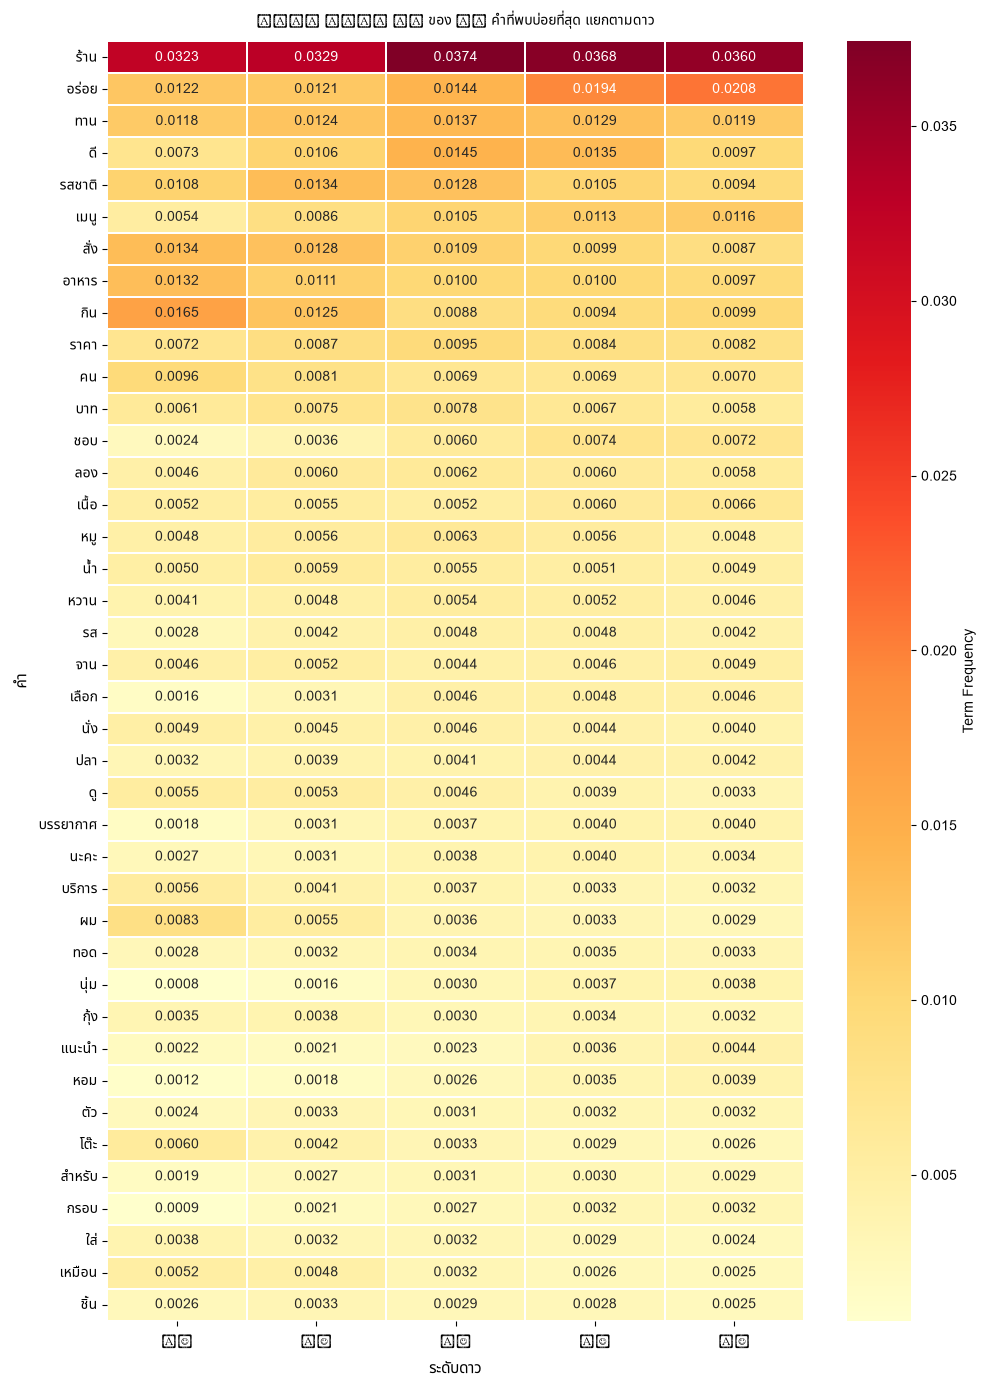

บันทึก heatmap.png แล้ว


In [13]:
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import seaborn as sns

TOP_N = 40
top_words = [word for word, _ in all_word_counts.most_common(TOP_N)]

tf_data = {}
for star in [0, 1, 2, 3, 4]:
    total = class_total_words[star]
    tf_data[f"{star+1}★"] = [
        class_word_counts[star].get(w, 0) / total
        for w in top_words
    ]

tf_df = pd.DataFrame(tf_data, index=top_words)

fig, ax = plt.subplots(figsize=(10, 14))
sns.heatmap(tf_df, annot=True, fmt=".4f", cmap="YlOrRd",
            linewidths=0.3, ax=ax, cbar_kws={"label": "Term Frequency"})

# ✅ ใส่ Thai font ให้ทุก label
for label in ax.get_yticklabels():
    label.set_fontproperties(prop)
for label in ax.get_xticklabels():
    label.set_fontproperties(prop)
ax.set_title(f"Heat Map: TF ของ {TOP_N} คำที่พบบ่อยที่สุด แยกตามดาว",
             fontsize=13, pad=12, fontproperties=prop)
ax.set_xlabel("ระดับดาว", fontsize=11, fontproperties=prop)
ax.set_ylabel("คำ", fontsize=11, fontproperties=prop)

plt.tight_layout()
plt.savefig("heatmap.png", dpi=150, bbox_inches="tight")
plt.show()
print("บันทึก heatmap.png แล้ว")

สร้าง Word cloude


C:\Users\maete\AppData\Local\Temp\ipykernel_26688\759141658.py:41: UserWarning: Glyph 3619 (\N{THAI CHARACTER RO RUA}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\maete\AppData\Local\Temp\ipykernel_26688\759141658.py:41: UserWarning: Glyph 3623 (\N{THAI CHARACTER WO WAEN}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\maete\AppData\Local\Temp\ipykernel_26688\759141658.py:41: UserWarning: Glyph 3617 (\N{THAI CHARACTER MO MA}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\maete\AppData\Local\Temp\ipykernel_26688\759141658.py:41: UserWarning: Glyph 3604 (\N{THAI CHARACTER DO DEK}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\maete\AppData\Local\Temp\ipykernel_26688\759141658.py:41: UserWarning: Glyph 3634 (\N{THAI CHARACTER SARA AA}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\maete\AppData\Local\Temp\ipykernel_26688\759141658.py:42: UserWarning: Glyph 3619 (\N{THAI CHARACTER RO RUA}) missing from font(s) Arial.
  plt.savefi

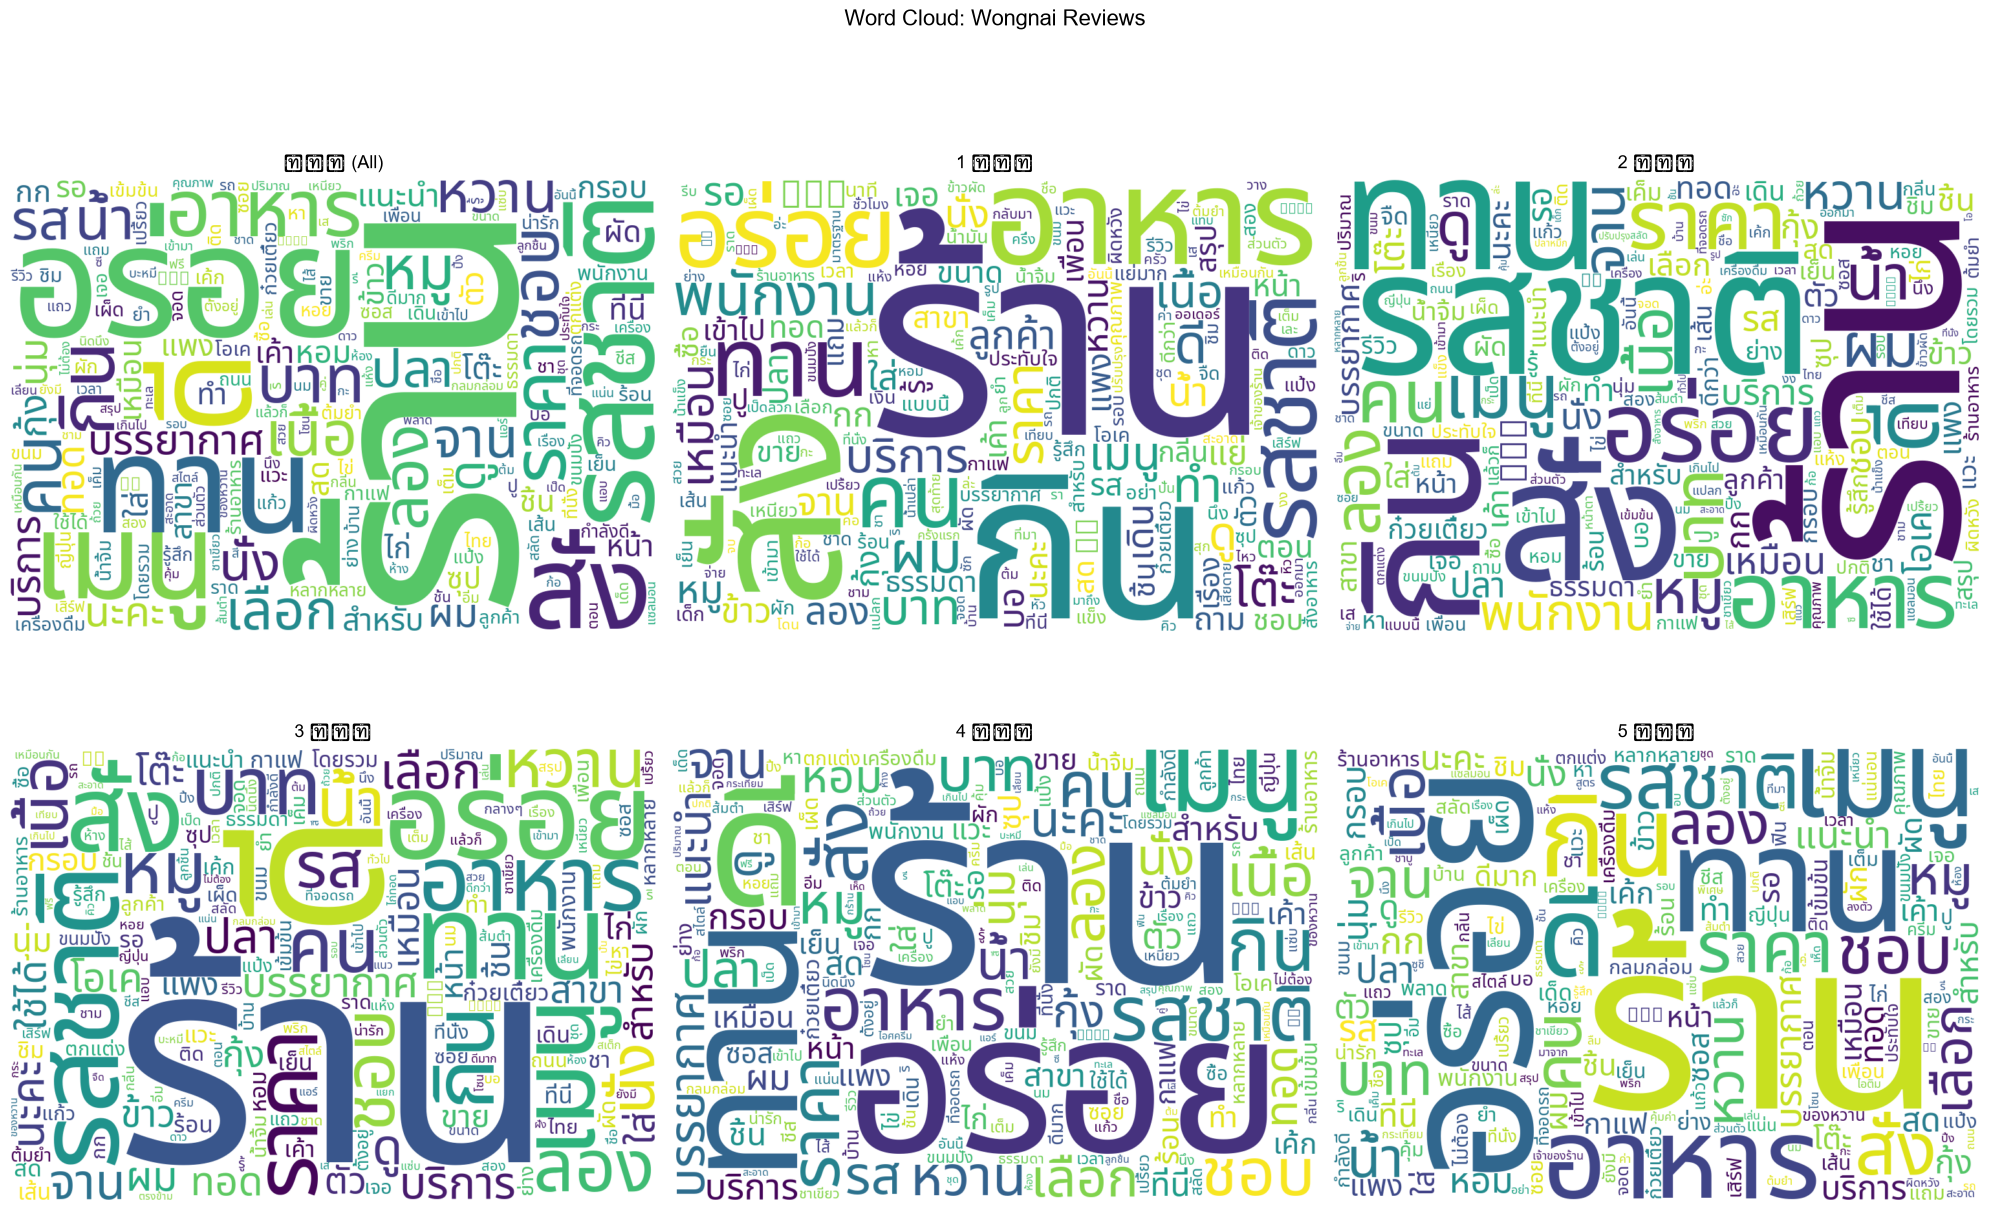

บันทึก wordclouds.png แล้ว


In [15]:
from wordcloud import WordCloud

# --- หา font สำหรับ WordCloud ---
# ต้องการ .ttf ที่รองรับภาษาไทย
# ถ้ายังไม่มี: pip install thai-word-cloud  หรือโหลด THSarabunNew.ttf

wc_font = font_path  # ใช้ font เดิมที่หาได้ด้านบน

def make_wordcloud(word_freq, title, font_path=None):
    """สร้าง WordCloud จาก dict {word: count}"""
    if not word_freq:
        return None
    kwargs = dict(
        width=1000, height=700,
        background_color="white",
        max_words=200,
        colormap="viridis",
        prefer_horizontal=0.7,
    )
    if font_path:
        kwargs["font_path"] = font_path
    wc = WordCloud(**kwargs)
    wc.generate_from_frequencies(word_freq)
    return wc

# --- สร้าง 6 Word Cloud ---
titles = ["รวม (All)"] + [f"{s+1} ดาว" for s in [0, 1, 2, 3, 4]]
freqs  = [dict(all_word_counts)] + [dict(class_word_counts[s]) for s in [0, 1, 2, 3, 4]]

fig, axes = plt.subplots(2, 3, figsize=(20, 13))
fig.suptitle("Word Cloud: Wongnai Reviews", fontsize=16, y=1.01)
axes = axes.flatten()

for i, (title, freq) in enumerate(zip(titles, freqs)):
    wc = make_wordcloud(freq, title, font_path=wc_font)
    if wc:
        axes[i].imshow(wc, interpolation="bilinear")
    axes[i].set_title(title, fontsize=13, pad=8)
    axes[i].axis("off")

plt.tight_layout()
plt.savefig("wordclouds.png", dpi=150, bbox_inches="tight")
plt.show()
print("บันทึก wordclouds.png แล้ว")

5.Naive Bayes


In [18]:
import math

STARS = [0, 1, 2, 3, 4]
vocab  = set(all_word_counts.keys())
V      = len(vocab)          # ขนาด vocabulary

# --- Prior probability (log) ---
total_docs = len(train_df)
class_doc_counts = train_df["star_rating"].value_counts().to_dict()
log_prior = {
    star: math.log(class_doc_counts[star] / total_docs)
    for star in STARS
}

# --- Log-likelihood ด้วย Laplace Smoothing ---
# P(word | class) = (count(word, class) + 1) / (total_words_in_class + |V|)
log_likelihood = {}
for star in STARS:
    log_likelihood[star] = {}
    denom = class_total_words[star] + V      # Laplace denominator
    for word in vocab:
        numerator = class_word_counts[star].get(word, 0) + 1   # Laplace +1
        log_likelihood[star][word] = math.log(numerator / denom)

# --- Predict function ---
def predict(text):
    tokens = preprocess(text)
    scores = {}
    for star in STARS:
        score = log_prior[star]
        denom = class_total_words[star] + V
        for token in tokens:
            if token in vocab:
                score += log_likelihood[star][token]
            else:
                # OOV word → Laplace: (0+1)/(total+V)
                score += math.log(1 / denom)
        scores[star] = score
    return max(scores, key=scores.get)


กำลัง test model...


100%|██████████| 6203/6203 [00:07<00:00, 884.25it/s] 



       PERFORMANCE TESTING RESULTS
Test samples : 6,203
Correct      : 3,202
Overall Accuracy: 0.5162  (51.62%)
---------------------------------------------
Accuracy แยกตามดาว:
  1 ดาว :    0/  50 = 0.0%
  2 ดาว :   18/ 206 = 8.7%
  3 ดาว :  953/1906 = 50.0%
  4 ดาว : 1988/2977 = 66.8%
  5 ดาว :  243/1064 = 22.8%


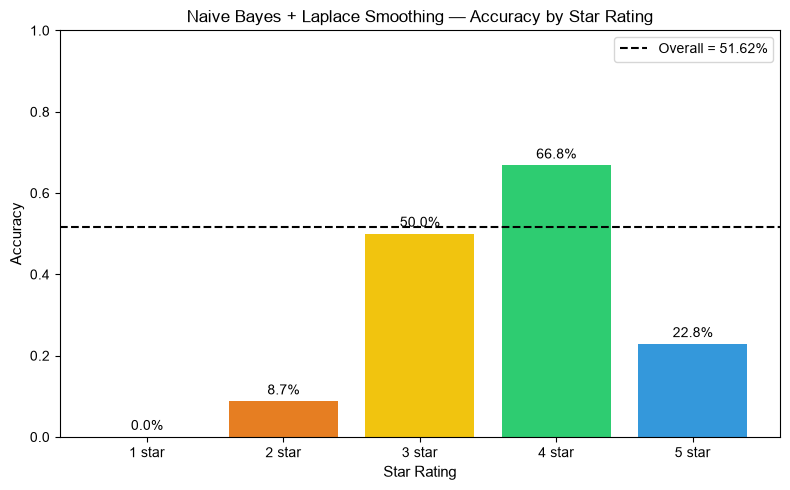

บันทึก accuracy_chart.png แล้ว — งานเสร็จ!


In [21]:
from tqdm import tqdm
from collections import defaultdict

print("กำลัง test model...")
correct = 0
total   = len(test_df)
per_class_correct = defaultdict(int)
per_class_total   = defaultdict(int)

for _, row in tqdm(test_df.iterrows(), total=total):
    pred = predict(row["review_body"])
    true = row["star_rating"]
    per_class_total[true] += 1
    if pred == true:
        correct += 1
        per_class_correct[true] += 1

overall_acc = correct / total

print("\n" + "="*45)
print("       PERFORMANCE TESTING RESULTS")
print("="*45)
print(f"Test samples : {total:,}")
print(f"Correct      : {correct:,}")
print(f"Overall Accuracy: {overall_acc:.4f}  ({overall_acc*100:.2f}%)")
print("-"*45)
print("Accuracy แยกตามดาว:")
for s in STARS:
    acc = per_class_correct[s] / per_class_total[s]
    print(f"  {s+1} ดาว : {per_class_correct[s]:4d}/{per_class_total[s]:4d} = {acc*100:.1f}%")
print("="*45)

# --- Bar chart ---
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(8, 5))

star_labels = ["1 star","2 star","3 star","4 star","5 star"]  # ✅ ใช้ ASCII แทน ★
star_accs   = [per_class_correct[s] / per_class_total[s] for s in STARS]
colors      = ["#e74c3c","#e67e22","#f1c40f","#2ecc71","#3498db"]

bars = ax.bar(star_labels, star_accs, color=colors)
ax.axhline(overall_acc, color="black", linestyle="--", linewidth=1.5,
           label=f"Overall = {overall_acc*100:.2f}%")
ax.set_ylim(0, 1)
ax.set_xlabel("Star Rating", fontsize=11)
ax.set_ylabel("Accuracy", fontsize=11)
ax.set_title("Naive Bayes + Laplace Smoothing — Accuracy by Star Rating", fontsize=12)
ax.legend()

for bar, acc in zip(bars, star_accs):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
            f"{acc*100:.1f}%", ha="center", va="bottom", fontsize=10)

plt.tight_layout()
plt.savefig("accuracy_chart.png", dpi=150, bbox_inches="tight")
plt.show()
print("บันทึก accuracy_chart.png แล้ว — งานเสร็จ!")